# The Riemann hypothesis, computed: look inside on your own machine

> **In plain words.** The notes tell the story; this notebook lets you compute every piece of it on your own
> computer. Each section opens with a plain paragraph like this one that says what its cells show; the technical
> details come after it, for those who want them. To follow along you only need to run the cells, top to bottom.

The companion to `notes.pdf`. Each section computes one piece of the lesson with mpmath: the prime staircase
π(x) against Gauss's li(x) and Riemann's R(x), Euler's product closing in on ζ(2), the first zeros of zeta and
what `zetazero` really returns, the hypothesis checked up to a height `T` by counting the zeros two ways, and
the prime staircase rebuilt from the zeros, one wave per zero.

Needs `mpmath` (`pip install mpmath`). `matplotlib` draws the figures when it is installed; every figure is also
printed as numbers. The default run takes a minute or two. `FULL = True` repeats the notes' scale: π(x)
up to 10¹², the count up to T = 1000 (the long part: about 9 minutes
on our laptop) and 100 zeros in the formula.

Our run, for comparison: Python 3.12.7, mpmath 1.3.0, sympy 1.14.0, on arm64.

In [1]:
FULL = False                       # True: the notes' scale (pi(x) to 10^12, T = 1000, 100 zeros); takes a while
K_MAX = 12 if FULL else 10         # count the primes up to 10^K_MAX
T = 1000.0 if FULL else 100.0      # height for the two-way count (section 4): any height that isn't a zero
ZEROS = 100 if FULL else 30        # zeros used in the explicit formula (section 5)

import inspect
import math
import platform

import mpmath as mp
from mpmath.functions import zetazeros   # the module behind mp.zetazero, read in section 3

try:
    import matplotlib.pyplot as plt
except ImportError:                # the figures are optional; every cell also prints its numbers
    plt = None

mp.mp.dps = 20                     # working precision in decimal digits (mpmath's default is 15)
COLORS = {"primes": "#B57600", "smooth": "#1D5FD0", "zeros": "#1E7346", "error": "#B42A30", "muted": "#5C636E"}
print("Python", platform.python_version(), "| mpmath", mp.__version__, "|", platform.machine(),
      "| FULL =", FULL, "| K_MAX =", K_MAX, "| T =", T, "| ZEROS =", ZEROS)

Python 3.12.7 | mpmath 1.3.0 | arm64 | FULL = False | K_MAX = 10 | T = 100.0 | ZEROS = 30


## 1. The staircase π(x), Gauss's li(x) and Riemann's R(x)

> **In plain words.** These cells count the prime numbers up to bigger and bigger limits and compare the count
> with Gauss's smooth curve and with Riemann's better one. The table shows how far off each curve is; the
> pictures show the staircase of primes with the two curves laid over it, and how slowly the errors grow.

π(x) counts the primes up to x: one step up at every prime, 25 steps by x = 100.
Gauss's guess is that near x about one number in log x is prime; adding that up gives
li(x) = ∫₀ˣ dt / log t (mpmath's `li`, the principal value). Riemann's refinement is
R(x) = Σ μ(n)/n · li(x^(1/n)) (`riemannr`): li(x), minus half of li(√x), minus a third of li(∛x), and so on.

Counting the primes up to 10¹² with a sieve would need a table of 10¹² entries. `prime_pi` below uses Lucy
Hedgehog's method instead: for each of the values v = x // k (about 2·√x of them) it keeps how many of 2…v
survive sieving by the primes found so far, and removes the multiples of each new prime p in one subtraction.

Look at the last three columns: li(x) − π(x) grows, but far more slowly than π(x); R(x) − π(x) is much smaller
and changes sign; and both stay far below √x·log x. Our bench (`sympy.primepi` for the counts) found
π(10¹²) = 37,607,912,018, li(10¹²) = 37,607,950,281 (off by
38,263) and R(10¹²) − π(10¹²) = -1,475.8.
The quick run stops at 10¹⁰; `FULL = True` goes to 10¹².

                x           pi(x)               li(x)    li - pi     R - pi  sqrt(x)*log(x)
               10               4     6.1655995047873     2.1656   0.564583               7
              100              25    30.1261415840796    5.12614   0.661633              46
            1,000             168    177.609657990152    9.60966   0.359446             218
           10,000           1,229    1246.13721589939    17.1372   -2.06878             921
          100,000           9,592     9629.8090010508     37.809   -4.56826           3,641
        1,000,000          78,498    78627.5491594622    129.549    29.3994          13,816
       10,000,000         664,579    664918.405048569    339.405    88.4476          50,970
      100,000,000       5,761,455    5762209.37544803    754.375    96.8673         184,207


    1,000,000,000      50,847,534    50849234.9570018    1700.96   -78.5723         655,327


   10,000,000,000     455,052,511    455055614.586623    3103.59   -1827.69       2,302,585

the primes below 100: [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97] -> 25


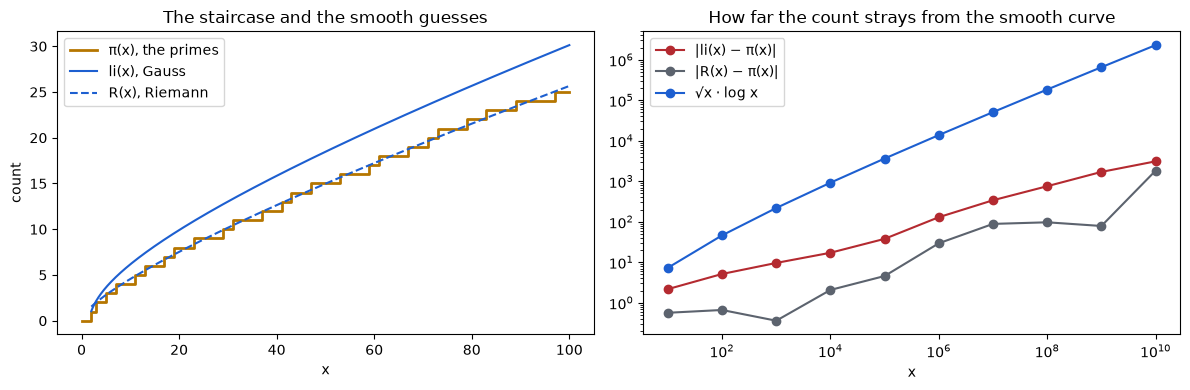

In [2]:
def prime_pi(x: int) -> int:
    """pi(x) by Lucy Hedgehog's method: S[v] = how many of 2..v survive sieving by the primes seen so far."""
    r = math.isqrt(x)
    V = [x // k for k in range(1, r + 1)]
    V += list(range(V[-1] - 1, 0, -1))
    S = {v: v - 1 for v in V}                  # before any sieving: all of 2..v
    for p in range(2, r + 1):
        if S[p] > S[p - 1]:                    # p survived the smaller primes, so p is prime
            sp, p2 = S[p - 1], p * p
            for v in V:                        # V is decreasing: stop below p^2
                if v < p2:
                    break
                S[v] -= S[v // p] - sp         # drop the multiples of p whose smallest prime factor is p
    return S[x]


rows = []
print(f"{'x':>17} {'pi(x)':>15} {'li(x)':>19} {'li - pi':>10} {'R - pi':>10} {'sqrt(x)*log(x)':>15}")
for k in range(1, K_MAX + 1):
    x = 10 ** k
    pi = prime_pi(x)
    li, R, scale = mp.li(x), mp.riemannr(x), mp.sqrt(x) * mp.log(x)
    rows.append((x, pi, float(li - pi), float(R - pi), float(scale)))
    print(f"{x:>17,} {pi:>15,} {mp.nstr(li, 15):>19} {mp.nstr(li - pi, 6):>10} {mp.nstr(R - pi, 6):>10} "
          f"{float(scale):>15,.0f}")

SMALL = [p for p in range(2, 101) if all(p % q for q in range(2, math.isqrt(p) + 1))]
print("\nthe primes below 100:", SMALL, "->", len(SMALL))

if plt:
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
    xs = [i / 10 for i in range(20, 1001)]
    a.step([0] + SMALL + [100], [0] + list(range(1, len(SMALL) + 1)) + [len(SMALL)], where="post",
           color=COLORS["primes"], lw=2, label="π(x), the primes")
    a.plot(xs, [float(mp.li(x)) for x in xs], color=COLORS["smooth"], label="li(x), Gauss")
    a.plot(xs, [float(mp.riemannr(x)) for x in xs], "--", color=COLORS["smooth"], label="R(x), Riemann")
    a.set(xlabel="x", ylabel="count", title="The staircase and the smooth guesses")
    a.legend()
    X = [r[0] for r in rows]
    b.loglog(X, [abs(r[2]) for r in rows], "o-", color=COLORS["error"], label="|li(x) − π(x)|")
    b.loglog(X, [abs(r[3]) for r in rows], "o-", color=COLORS["muted"], label="|R(x) − π(x)|")
    b.loglog(X, [r[4] for r in rows], "o-", color=COLORS["smooth"], label="√x · log x")
    b.set(xlabel="x", title="How far the count strays from the smooth curve")
    b.legend()
    plt.tight_layout()
    plt.show()

## 2. Euler's product: the primes are built into zeta

> **In plain words.** One over every square number, added up, gives π²/6. Here the same number is built from the
> primes alone, by multiplying in one factor per prime, and the first cell shows the two getting closer as more
> primes are used. The second cell shows why it works: multiplying out the factors produces every whole number
> exactly once.

Add 1/n² over every whole number and the sum closes in on π²/6 = 1.64493406685. Multiply 1/(1 − 1/p²) over
the primes only, and the product closes in on the very same number: our bench, with every prime up to
99,991, got 1.644932747, short by 1.3e-06.

Why: each factor is a geometric series, 1/(1 − 1/p²) = 1 + 1/p² + 1/p⁴ + …. Multiplying the factors out picks
one power of each prime, so every term is 1/n² for one whole number n = 2ᵃ·3ᵇ·5ᶜ…, and because every whole
number factors into primes in exactly one way, each n turns up exactly once. The second cell multiplies out the
factors for 2, 3, 5 and 7 and checks it. That identity, Σ 1/nˢ = Π 1/(1 − p⁻ˢ), is why Riemann's ζ(s) is
"built out of the primes".

In [3]:
LIMIT = 100_000
sieve = bytearray([1]) * (LIMIT + 1)
sieve[0] = sieve[1] = 0
for p in range(2, math.isqrt(LIMIT) + 1):
    if sieve[p]:
        sieve[p * p::p] = bytes(len(range(p * p, LIMIT + 1, p)))
PRIMES = [p for p in range(LIMIT + 1) if sieve[p]]

target = mp.zeta(2)
print("zeta(2) =", target, "  pi^2/6 =", mp.pi ** 2 / 6)
marks = {2, 3, 5, 7, 11, 13, 29, 97, 997, 9973, 99991}
prod, total, n = mp.mpf(1), mp.mpf(0), 0
print(f"\n{'P':>7} {'product over primes p <= P':>28} {'gap':>10}   {'sum of 1/n^2 for n <= P':>25} {'gap':>10}")
for p in PRIMES:
    prod *= 1 / (1 - mp.mpf(p) ** -2)
    while n < p:
        n += 1
        total += mp.mpf(1) / n ** 2
    if p in marks:
        print(f"{p:>7} {mp.nstr(prod, 12):>28} {mp.nstr(target - prod, 3):>10}   {mp.nstr(total, 12):>25} "
              f"{mp.nstr(target - total, 3):>10}")

zeta(2) = 1.6449340668482264365   pi^2/6 = 1.6449340668482264365

      P   product over primes p <= P        gap     sum of 1/n^2 for n <= P        gap
      2                1.33333333333      0.312                        1.25      0.395
      3                          1.5      0.145               1.36111111111      0.284
      5                       1.5625     0.0824               1.46361111111      0.181
      7                1.59505208333     0.0499               1.51179705215      0.133
     11                1.60834418403     0.0366               1.55803219398     0.0869
     13                1.61791766131      0.027               1.57089379818      0.074
     29                 1.6330704905     0.0119               1.61103900649     0.0339
     97                1.64194519662    0.00299                1.6346777465     0.0103
    997                1.64472519024   0.000209               1.64393156067      0.001
   9973                1.64491792075    1.61e-5               1.

  99991                 1.6449327472    1.32e-6                 1.644924066     1.0e-5


In [4]:
# Multiply out (1 + 1/2² + 1/4² + …)(1 + 1/3² + …)(1 + 1/5² + …)(1 + 1/7² + …), keeping the terms 1/n² with n <= 60
terms = {1: 1}                        # n -> how many times the term 1/n² came out
for p in (2, 3, 5, 7):
    grown = {}
    for m, count in terms.items():
        q = m
        while q <= 60:                # m times every power of p
            grown[q] = grown.get(q, 0) + count
            q *= p
    terms = grown
print("n that came out:", sorted(terms))
print("each one exactly once:", set(terms.values()) == {1})
print("never came out (each needs a prime above 7):", [m for m in range(1, 61) if m not in terms])

n that came out: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 15, 16, 18, 20, 21, 24, 25, 27, 28, 30, 32, 35, 36, 40, 42, 45, 48, 49, 50, 54, 56, 60]
each one exactly once: True
never came out (each needs a prime above 7): [11, 13, 17, 19, 22, 23, 26, 29, 31, 33, 34, 37, 38, 39, 41, 43, 44, 46, 47, 51, 52, 53, 55, 57, 58, 59]


## 3. The zeros, and what `zetazero` really returns

> **In plain words.** These cells ask mpmath for the first zeros of zeta (each one: one half across, some height
> up), check that zeta really is zero there, and open mpmath's own code to show that it fills in the one half
> itself. Then they walk up the halfway line and mark every place where a related number flips sign: each flip
> is a zero.

The sum only makes sense for Re s > 1, but zeta extends, in exactly one smooth way, to every complex s except
s = 1, and mpmath's `zeta` computes that extension. It is zero at −2, −4, −6, … (the trivial zeros), and every
other zero lies in the strip 0 < Re s < 1. Our bench printed the first three as

```
(0.5 + 14.1347251417347j)
(0.5 + 21.0220396387716j)
(0.5 + 25.0108575801457j)
```

Look at three things below. First, |ζ| really is 0 at each zero, to the working precision: the cell works to
mpmath's default 15 digits, so |ζ| comes out about as small as 15 digits can show; the bench
worked to 20 digits and found at most 6.74e-18 over the first 1,000 zeros.
Second, the line in mpmath's own source that builds the answer: `zetazero` locates t as a sign change of
Hardy's Z function on the line and returns `mpc(0.5, t)`,
so the real part is 0.5 by construction; for n below 400 million it also relies on a stored list of
the known exceptions to Rosser's rule. Third, Z itself: e^{iθ(t)}·ζ(1/2 + it) is a real number, so each sign change of Z(t)
is a zero on the line. Below height 50 there are ten (the tenth at 49.77).

In [5]:
print("zeta(2)  =", mp.zeta(2))
print("zeta(-1) =", mp.zeta(-1), "  <- the extension's value; the sum 1 + 2 + 3 + ... itself diverges")
for m in (-2, -4, -6, -8, -10):
    print(f"zeta({m}) = {mp.zeta(m)}")
try:
    mp.zeta(1)
except ValueError as e:
    print("zeta(1):", e)

print()
with mp.workdps(15):                  # mpmath's default precision: what print(zetazero(n)) shows
    for m in range(1, 11):
        rho = mp.zetazero(m)
        print(f"zetazero({m:>2}) = {rho}    |zeta(rho)| = {mp.nstr(abs(mp.zeta(rho)), 2)}")

zeta(2)  = 1.6449340668482264365
zeta(-1) = -0.083333333333333333333   <- the extension's value; the sum 1 + 2 + 3 + ... itself diverges
zeta(-2) = 0.0
zeta(-4) = 0.0
zeta(-6) = 0.0
zeta(-8) = 0.0
zeta(-10) = 0.0
zeta(1): zeta(1) pole

zetazero( 1) = (0.5 + 14.1347251417347j)    |zeta(rho)| = 6.7e-16
zetazero( 2) = (0.5 + 21.0220396387716j)    |zeta(rho)| = 1.2e-15
zetazero( 3) = (0.5 + 25.0108575801457j)    |zeta(rho)| = 8.5e-16
zetazero( 4) = (0.5 + 30.4248761258595j)    |zeta(rho)| = 1.1e-15
zetazero( 5) = (0.5 + 32.9350615877392j)    |zeta(rho)| = 2.7e-15
zetazero( 6) = (0.5 + 37.5861781588257j)    |zeta(rho)| = 6.7e-15
zetazero( 7) = (0.5 + 40.9187190121475j)    |zeta(rho)| = 4.8e-15
zetazero( 8) = (0.5 + 43.327073280915j)    |zeta(rho)| = 4.3e-15
zetazero( 9) = (0.5 + 48.0051508811672j)    |zeta(rho)| = 2.0e-15
zetazero(10) = (0.5 + 49.7738324776723j)    |zeta(rho)| = 2.4e-15


mpmath.functions.zetazeros.zetazero, line 83 of the function:
    v = ctx.mpc(0.5,t)

stored Rosser-rule exceptions (used for n < 400,000,000): 386

zetazero(1, info=True): (mpc(real='0.5', imag='14.134725141734693790451'), [-1, 0], 1, '(1)')
   (the zero, the Gram points around its block, its place in the block, the block's pattern of zeros)

Hardy's Z(t) = e^(i theta(t)) * zeta(1/2 + it) is real:
  t =     10.0:     -1.5491945 + (-2.0e-21)i    siegelz(t) = -1.5491945
  t =  14.1347:  -1.9941388e-5 + (8.6e-27)i    siegelz(t) = -1.9941388e-5
  t =     20.0:      1.1478424 + (1.1e-21)i    siegelz(t) = 1.1478424
  t =   21.022:      4.5063e-5 + (1.8e-26)i    siegelz(t) = 4.5063e-5
  t =     30.0:     0.59602852 + (3.5e-21)i    siegelz(t) = 0.59602852



sign changes of Z(t) for 0 < t <= 50: 10, near t = [14.12, 21.02, 25.02, 30.42, 32.92, 37.58, 40.92, 43.33, 48.02, 49.77]


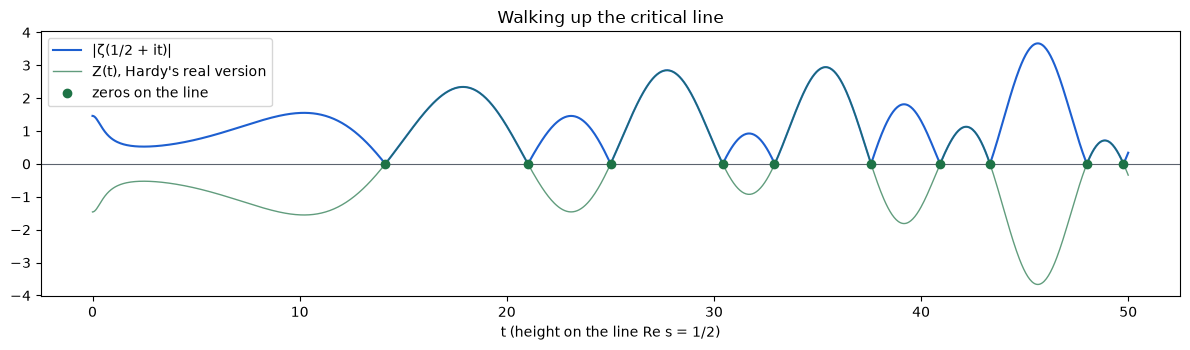

In [6]:
src = inspect.getsource(zetazeros.zetazero).splitlines()
for i, line in enumerate(src, 1):
    if "mpc(0.5" in line:
        print(f"{zetazeros.__name__}.zetazero, line {i} of the function:\n    {line.strip()}")
exceptions = getattr(zetazeros, "_ROSSER_EXCEPTIONS", None)
if exceptions is not None:
    print(f"\nstored Rosser-rule exceptions (used for n < 400,000,000): {len(exceptions) // 2}")
print("\nzetazero(1, info=True):", mp.zetazero(1, info=True))
print("   (the zero, the Gram points around its block, its place in the block, the block's pattern of zeros)")

print("\nHardy's Z(t) = e^(i theta(t)) * zeta(1/2 + it) is real:")
for t in (mp.mpf(10), mp.mpf("14.1347"), mp.mpf(20), mp.mpf("21.0220"), mp.mpf(30)):
    z = mp.exp(1j * mp.siegeltheta(t)) * mp.zeta(mp.mpc(0.5, t))
    print(f"  t = {mp.nstr(t, 6):>8}:  {mp.nstr(z.real, 8):>13} + ({mp.nstr(z.imag, 2)})i    "
          f"siegelz(t) = {mp.nstr(mp.siegelz(t), 8)}")

ts = [i / 20 for i in range(0, 1001)]          # t = 0 .. 50
Z = [float(mp.siegelz(t)) for t in ts]
flips = [round((ts[i] + ts[i + 1]) / 2, 2) for i in range(len(Z) - 1) if (Z[i] > 0) != (Z[i + 1] > 0)]
print(f"\nsign changes of Z(t) for 0 < t <= 50: {len(flips)}, near t = {flips}")

if plt:
    fig, ax = plt.subplots(figsize=(12, 3.6))
    ax.plot(ts, [abs(v) for v in Z], color=COLORS["smooth"], label="|ζ(1/2 + it)|")
    ax.plot(ts, Z, color=COLORS["zeros"], lw=1, alpha=0.7, label="Z(t), Hardy's real version")
    ax.axhline(0, color=COLORS["muted"], lw=0.8)
    ax.plot(flips, [0] * len(flips), "o", color=COLORS["zeros"], label="zeros on the line")
    ax.set(xlabel="t (height on the line Re s = 1/2)", title="Walking up the critical line")
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

## 4. Check it yourself: count the zeros below T two ways

> **In plain words.** The check from the video. Count every zero up to a height, wherever it sits, by walking
> around the edge of the region; then count only the zeros on the halfway line, by counting sign flips. If the
> two counts agree, no zero up to that height is off the line. The quick run checks up to height 100;
> you can raise it.

Because `zetazero` only looks on the line, it can't test the hypothesis. Counting can.

1. **Every zero in the strip**, wherever it sits. The argument principle counts the zeros inside a closed
   curve by how many times ζ winds around 0 along it. For the strip up to height T this becomes
   N(T) = θ(T)/π + 1 + S(T), with θ the Riemann–Siegel theta function and S(T) = arg ζ(1/2 + iT)/π, the
   argument followed continuously along Im s = T from 3 + iT (where ζ is close to 1) to 1/2 + iT. N(T) counts
   zeros, so the sum has to land on a whole number.
2. **The zeros on the line**: every sign change of Z(t) on a fine grid is one.

Sign changes ≤ zeros on the line ≤ N(T). When the two counts are equal, no zero below T is off the line. Our
bench at T = 1000: θ(T)/π = 647.6162419, S(T) = 0.38375806, so
N(T) = 649 → 649; Z(t) changed sign 649
times on a grid of step 0.01; `zetazero` listed 649. At the default
T = 100, expect 29: that many of the bench's first
1,000 zeros lie below 100. The same code is `code/check_rh.py`.

In [7]:
def count_in_strip(T: float) -> dict:
    """N(T) = theta(T)/pi + 1 + S(T); S(T) from the continuous change of arg zeta along Im s = T."""
    with mp.workdps(20):
        theta = mp.siegeltheta(T)
        sig, step = mp.mpf(3), mp.mpf("0.002")
        prev = mp.zeta(mp.mpc(sig, T))
        arg, biggest = mp.arg(prev), mp.mpf(0)
        while sig > 0.5:
            sig = max(mp.mpf(0.5), sig - step)
            cur = mp.zeta(mp.mpc(sig, T))
            d = mp.arg(cur / prev)              # this step's change of the argument, in (-pi, pi]
            biggest = max(biggest, abs(d))
            arg += d
            prev = cur
        S = arg / mp.pi
        N = theta / mp.pi + 1 + S
        return {"theta_over_pi": theta / mp.pi, "S": S, "N_exact": N, "N": int(mp.nint(N)),
                "largest_step": biggest, "abs_zeta_at_T": abs(prev)}


def count_on_line(T: float, grid: float = 0.01) -> int:
    """Sign changes of Hardy's Z(t) for t = 1, 1 + grid, ... <= T."""
    with mp.workdps(15):
        n, prev, k = 0, mp.siegelz(1), 1
        while 1 + k * grid <= T:
            z = mp.siegelz(1 + k * grid)
            n += (z > 0) != (prev > 0)
            prev, k = z, k + 1
        if 1 + (k - 1) * grid < T:              # a coarse grid stops short of T: sample T itself too
            n += (mp.siegelz(T) > 0) != (prev > 0)
        return n


def count_two_ways(T: float, grid: float = 0.01) -> bool:
    strip = count_in_strip(T)
    assert strip["abs_zeta_at_T"] > 1e-3, "T sits (almost) on a zero: pick another height"
    on_line = count_on_line(T, grid)
    print(f"T = {T:g}")
    print(f"  in the strip:  theta(T)/pi = {mp.nstr(strip['theta_over_pi'], 10)},  S(T) = {mp.nstr(strip['S'], 8)}"
          f"  ->  N(T) = {mp.nstr(strip['N_exact'], 10)} = {strip['N']}   (largest arg step "
          f"{mp.nstr(strip['largest_step'], 3)} rad)")
    print(f"  on the line:   {on_line} sign changes of Z(t), grid step {grid:g}")
    agree = strip["N"] == on_line and abs(strip["N_exact"] - strip["N"]) < 0.01
    print("  agree:", agree, "-> no zero off the line below T" if agree else "-> look closer (grid? precision?)")
    return agree


count_two_ways(T)

with mp.workdps(15):
    listed = 0
    while mp.zetazero(listed + 1).imag <= T:
        listed += 1
print(f"  zetazero's own list below T: {listed} (found on the line only, so it can't see a zero off it)")

T = 100
  in the strip:  theta(T)/pi = 28.0024099,  S(T) = -0.0024099023  ->  N(T) = 29.0 = 29   (largest arg step 0.000165 rad)
  on the line:   29 sign changes of Z(t), grid step 0.01
  agree: True -> no zero off the line below T


  zetazero's own list below T: 29 (found on the line only, so it can't see a zero off it)


## 5. The staircase rebuilt from the zeros: one wave per zero

> **In plain words.** Riemann's exact formula: a smooth curve plus one wave per zero gives back the staircase of
> primes. These cells compute each zero's wave, add more and more of them, and measure how close the result gets
> to the true staircase. The picture shows the curve snapping into steps at the primes.

Riemann's explicit formula, with π₀(x) the staircase that takes the midpoint at each jump:

π₀(x) = R(x) − Σ_ρ R(x^ρ) − 1/log x + arctan(π / log x)/π

The sum runs over the zeros ρ = β + iγ, which come in conjugate pairs, so each pair adds one real wave,
−2·Re R(x^ρ). Since x^ρ = x^β·e^{iγ·log x}, the height γ sets how fast the wave wiggles (in log x) and the real
part β sets how big it can grow (like x^β). The cell computes R(x^ρ) as Σ μ(n)/n · Ei(ρ·log x / n), not as
`riemannr(x**rho)`: that would take the principal log of x^ρ, which wraps once γ·log x passes π.

Look at the curves: with no zeros the curve is smooth; with each stage it sharpens into steps that land on
2, 3, 5, 7, 11, 13, …. The largest distance between curve and staircase in our bench, for x from
2 to 60 and at least 0.2 away from any jump:

| zeros used | 0 | 1 | 3 | 10 | 30 | 100 |
|---|---|---|---|---|---|---|
| largest error | 0.916 | 0.743 | 0.662 | 0.552 | 0.471 | 0.257 |

The quick run stops at `ZEROS` = 30; `FULL = True` adds the last column.

zeros used   largest |curve - pi(x)|, x in [2, 60], at least 0.2 from a jump
         0   0.916
         1   0.743
         3   0.662
        10   0.552
        30   0.471


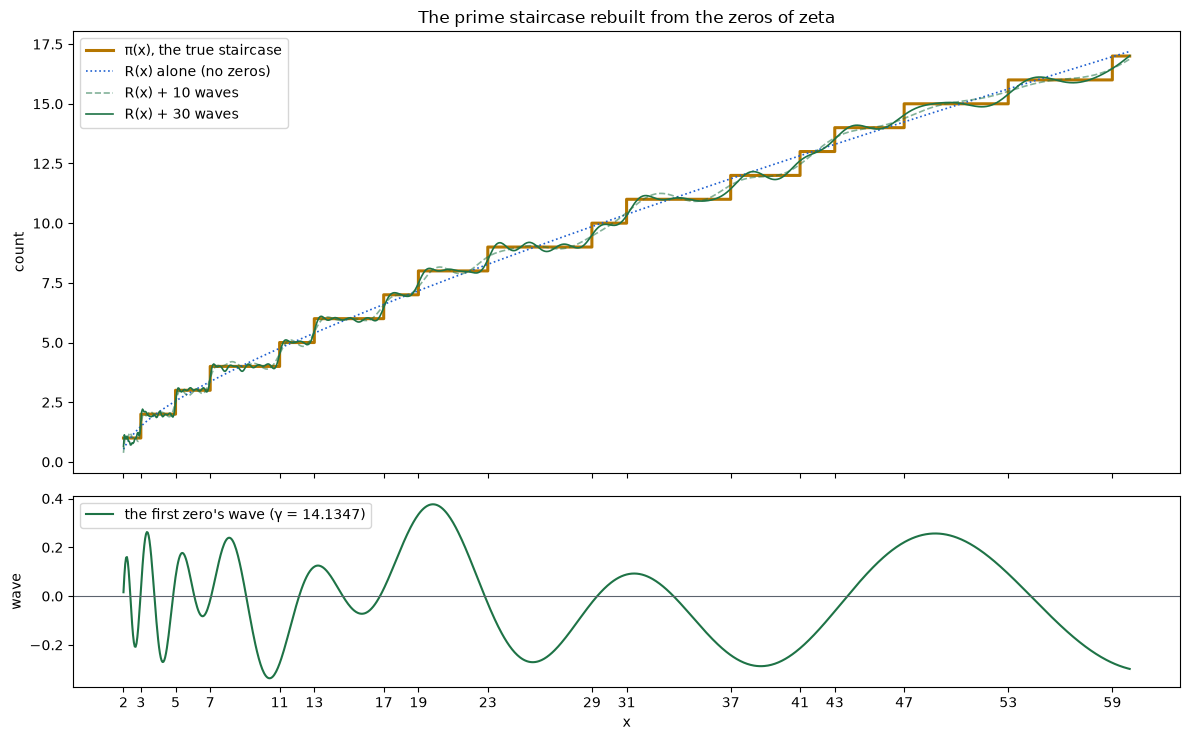

In [8]:
def mobius(n: int) -> int:
    mu, p = 1, 2
    while p * p <= n:
        if n % p == 0:
            n //= p
            if n % p == 0:
                return 0
            mu = -mu
        p += 1
    return -mu if n > 1 else mu


MOBIUS = [(n, mobius(n)) for n in range(1, 13) if mobius(n)]


def r_of_power(rho, lnx):
    """R(x^rho) on the branch the formula needs: sum of mu(n)/n * li(x^(rho/n)), with li(x^w) = Ei(w log x)."""
    return mp.fsum(m * mp.ei(rho * lnx / n) / n for n, m in MOBIUS)


def wave(rho, xs):
    """The wave one zero (with its conjugate) adds to the staircase: -2 Re R(x^rho)."""
    return [float(-2 * mp.re(r_of_power(rho, mp.log(x)))) for x in xs]


with mp.workdps(15):
    XS = [2 + i * 0.05 for i in range(int((60 - 2) / 0.05) + 1)]
    GAMMAS = [float(mp.zetazero(n).imag) for n in range(1, ZEROS + 1)]
    BASE = [float(mp.riemannr(x) - 1 / mp.log(x) + mp.atan(mp.pi / mp.log(x)) / mp.pi) for x in XS]
    WAVES = [wave(mp.mpc(0.5, g), XS) for g in GAMMAS]
TRUE = [sum(1 for p in SMALL if p <= x) for x in XS]


def rebuild(waves):
    """R(x) - 1/log x + arctan(pi/log x)/pi plus the given waves, on XS."""
    return [b + sum(w[i] for w in waves) for i, b in enumerate(BASE)]


def largest_error(curve):
    """Largest |curve - pi(x)| for x on XS at least 0.2 away from a whole number (the jumps are at primes)."""
    return max(abs(v - t) for v, t, x in zip(curve, TRUE, XS) if abs(x - round(x)) > 0.2)


curves = {k: rebuild(WAVES[:k]) for k in (0, 1, 3, 10, 30, 100) if k <= ZEROS}
print(f"{'zeros used':>10}   largest |curve - pi(x)|, x in [2, 60], at least 0.2 from a jump")
for k, c in curves.items():
    print(f"{k:>10}   {largest_error(c):.3f}")

if plt:
    fig, (a, b) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
    a.step(XS, TRUE, where="post", color=COLORS["primes"], lw=2.2, label="π(x), the true staircase")
    for k, style in ((0, ":"), (10, "--"), (30, "-" if ZEROS < 100 else "-."), (100, "-")):
        if k in curves:
            a.plot(XS, curves[k], style, lw=1.2 if k < 100 else 1.6,
                   color=COLORS["smooth"] if k == 0 else COLORS["zeros"],
                   alpha=0.55 if k == 10 else 1, label=f"R(x) + {k} waves" if k else "R(x) alone (no zeros)")
    a.set(ylabel="count", title="The prime staircase rebuilt from the zeros of zeta")
    a.set_xticks(SMALL[:17])
    a.legend(loc="upper left")
    b.plot(XS, WAVES[0], color=COLORS["zeros"], label=f"the first zero's wave (γ = {GAMMAS[0]:.4f})")
    b.axhline(0, color=COLORS["muted"], lw=0.8)
    b.set(xlabel="x", ylabel="wave")
    b.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

### Off the line (hypothetical)

> **In plain words.** A made-up experiment: what would a zero's wave look like if the zero sat off the halfway
> line? It grows far bigger than a real zero's wave, and that would make the primes much less evenly spread.

What if a zero had real part bigger than 1/2? Zeros off the line would come in pairs, β + iγ and (1 − β) + iγ,
mirrored across the line. Below, the real first zero's wave next to the wave of a made-up pair at the same
height with β = 0.8 and 0.2, for x up to 10⁴ (log scale). The made-up wave keeps growing,
roughly like x^β with β = 0.8 instead of √x; with a zero like that, the count of primes would stray
from the smooth curve by far more than √x·log x. No such zero has ever been found; the hypothesis says there
is none.

x =     10:  real zero's wave   -0.311   hypothetical pair's wave   -0.728
x =    100:  real zero's wave   -0.062   hypothetical pair's wave   -0.546
x =   1000:  real zero's wave    0.242   hypothetical pair's wave    1.685
x =  10000:  real zero's wave    1.579   hypothetical pair's wave   24.523


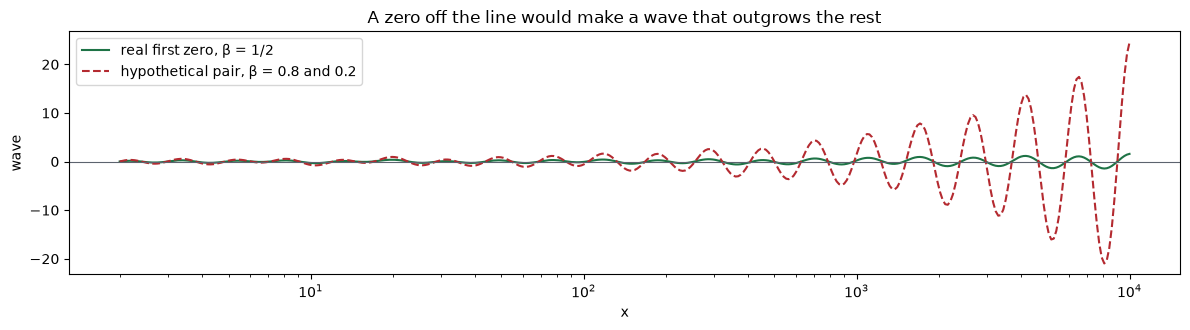

In [9]:
with mp.workdps(15):
    far = [10 ** (0.3 + i * 3.7 / 400) for i in range(401)]           # x from 2 to 10^4
    g1 = GAMMAS[0]
    on_line = wave(mp.mpc(0.5, g1), far)
    off_line = [a + b for a, b in zip(wave(mp.mpc(0.8, g1), far), wave(mp.mpc(0.2, g1), far))]
for x in (10, 100, 1000, 10000):
    i = min(range(len(far)), key=lambda j: abs(far[j] - x))
    print(f"x = {x:>6}:  real zero's wave {on_line[i]:>8.3f}   hypothetical pair's wave {off_line[i]:>8.3f}")
if plt:
    fig, ax = plt.subplots(figsize=(12, 3.4))
    ax.semilogx(far, on_line, color=COLORS["zeros"], label="real first zero, β = 1/2")
    ax.semilogx(far, off_line, "--", color=COLORS["error"], label="hypothetical pair, β = 0.8 and 0.2")
    ax.axhline(0, color=COLORS["muted"], lw=0.8)
    ax.set(xlabel="x", ylabel="wave", title="A zero off the line would make a wave that outgrows the rest")
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

## Your turn

> **In plain words.** Two experiments to try. Raise the height of the check, then make its steps too big and
> watch the two counts disagree. And move a zero off the line to see what it does to the rebuilt staircase.

1. **Raise `T`, then break the grid.** Run `count_two_ways(300)` (or set `FULL = True` for
   T = 1000, the notes' run). Then make the grid coarse, `count_two_ways(100, grid=2.0)`: the sign
   changes fall short of N(T), because the grid steps over pairs of close zeros. Two counts that disagree are
   the alarm; a coarse grid can't make them agree by accident.
2. **Push the first zero off the line.** Rebuild the staircase with the hypothetical pair in place of the first
   zero, and compare its largest error with the table in section 5:

   ```python
   pair = [a + b for a, b in zip(wave(mp.mpc(0.8, GAMMAS[0]), XS), wave(mp.mpc(0.2, GAMMAS[0]), XS))]
   largest_error(rebuild([pair] + WAVES[1:]))
   ```

   Then move it closer to the line (0.6 and 0.4): how far off can a zero sit before x up to 60 shows it?

Not a proof, and not meant as one: this is floating point, with step sizes chosen by hand. The record
verifications use the same two ideas with interval arithmetic and Turing's method, which certify every
digit; see the notes, section 7.